# Election dynamics: campaign visualization

This notebook compares a matched control and a deliberately high-impact campaign scenario in one constituency. It plots voter support and animates voter opinion over the campaign timeline. All data is synthetic. Strong campaign settings are chosen to make the mechanics visible, not calibrated as realistic effects.

Run from the repository root. Install packages with `python -m pip install -r requirements.txt`; run the notebook with Jupyter.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "election_sim").is_dir(): raise RuntimeError("Run this notebook from the repository root")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from constituency_loader import load_constituency
from election_sim import SimulationConfig, simulate
from election_sim.campaign.models import CampaignAction
DATA_DIR = ROOT / "data" / "synthetic_election_dataset"
SEED, DAYS, CONSTITUENCY_ID = 42, 30, 21
data = load_constituency(DATA_DIR, CONSTITUENCY_ID, election_duration_days=DAYS)


## Set up opposing campaigns

The two candidates with the most separated average issue positions campaign from day 8 through day 19. Reach, intensity, and campaign strength are deliberately high so the opinion movement is easy to see. The third candidate does not campaign.

In [2]:
candidates = data["candidates"].sort_values("candidate_id").reset_index(drop=True)
position_cols = [c for c in candidates.columns if c.startswith("position_")]
positions = candidates[position_cols].mean(axis=1)
left_idx, right_idx = int(positions.idxmin()), int(positions.idxmax())
chosen = candidates.iloc[[left_idx, right_idx]]
palette = ["#2563eb", "#e11d48", "#16a34a"]
colors = dict(zip(candidates.candidate_id, palette))
actions = [CampaignAction(f"demo_{row.candidate_id}", row.candidate_id, 8, 12, 1.0, 0.70)
           for row in chosen.itertuples()]
config = SimulationConfig(constituency_id=CONSTITUENCY_ID, days=DAYS, lambda_social=0.15,
                          lambda_campaign=0.90, lambda_event=0.0)
print("Candidates campaigning:", [a.candidate_id for a in actions])
print("Demonstration settings: 70% reach, full intensity, days 8–19")


Candidates campaigning: ['CAND_0061', 'CAND_0063']
Demonstration settings: 70% reach, full intensity, days 8–19


## Compare matched runs

Both runs use the same data and random seed. Campaigns are the only intended difference. The no-campaign control shows the baseline social dynamics.

In [3]:
control = simulate(config, data, seed=SEED, record_history=True)
treatment = simulate(config, data, seed=SEED, campaign_actions=actions, record_history=True)


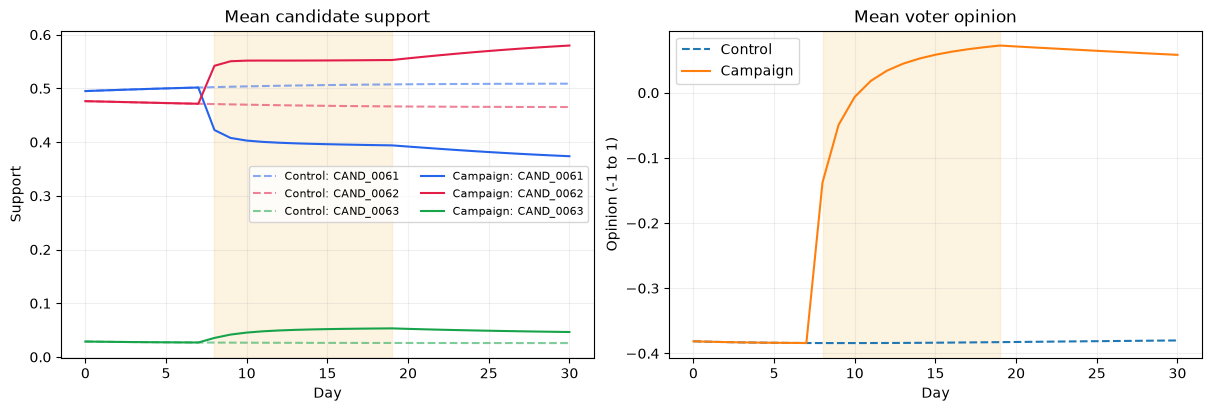

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for result, label, style in [(control, "Control", "--"), (treatment, "Campaign", "-")]:
    for cid, group in result.daily_support.groupby("candidate_id"):
        axes[0].plot(group.day, group.mean_support, style, color=colors[cid],
                     alpha=0.55 if label == "Control" else 1, label=f"{label}: {cid}")
    axes[1].plot(result.daily_summary.day, result.daily_summary.opinion_mean, style, label=label)
for ax in axes: ax.axvspan(8, 19, color="#f59e0b", alpha=0.12); ax.grid(alpha=0.2)
axes[0].set(title="Mean candidate support", xlabel="Day", ylabel="Support")
axes[1].set(title="Mean voter opinion", xlabel="Day", ylabel="Opinion (-1 to 1)")
axes[0].legend(fontsize=8, ncol=2); axes[1].legend(); plt.show()


## Animate voters in the constituency

Each dot is a voter sampled for display. Its horizontal position is opinion, color is the leading candidate, and size is support confidence. A dark outline marks voters reached by a campaign that day. The voter layout is illustrative rather than geographic.

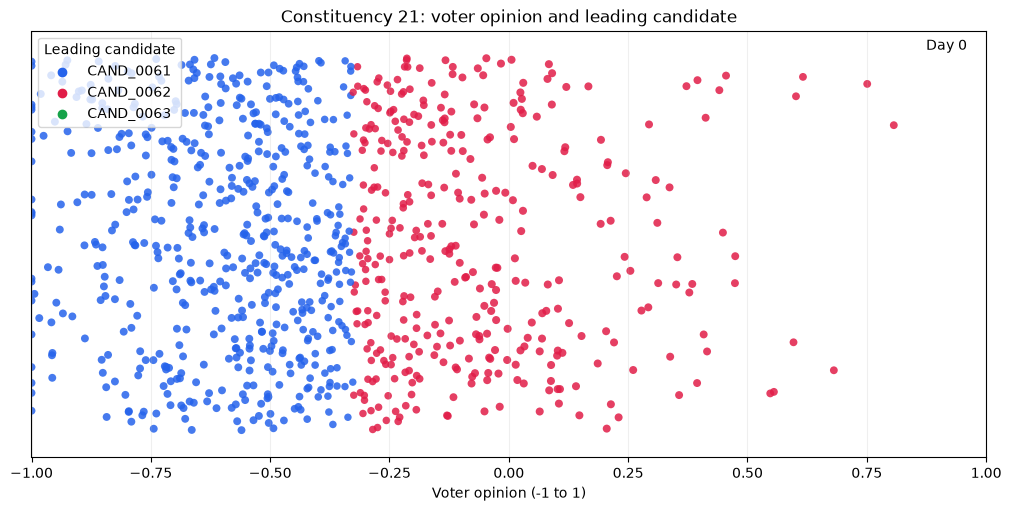

In [5]:
history = treatment.history
rng = np.random.default_rng(SEED)
count = history["opinions"].shape[1]
selected = np.sort(rng.choice(count, size=min(900, count), replace=False))
support = history["support"][:, selected, :]
leaders = support.argmax(axis=2)
point_colors = np.array(palette)[leaders]
sizes = 10 + 38 * support.max(axis=2)
exposed = (history["campaign_exposed"][:, selected, :].any(axis=2)
           if history["campaign_exposed"].shape[2] else np.zeros((DAYS+1, len(selected)), bool))
y = rng.uniform(-0.48, 0.48, len(selected))
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
points = ax.scatter(history["opinions"][0, selected], y, c=point_colors[0], s=sizes[0], edgecolors="none", alpha=0.85)
ax.set(xlim=(-1, 1), ylim=(-0.55, 0.55), yticks=[], xlabel="Voter opinion (-1 to 1)",
       title=f"Constituency {CONSTITUENCY_ID}: voter opinion and leading candidate")
ax.grid(axis="x", alpha=0.2)
for cid, color in colors.items(): ax.scatter([], [], color=color, label=cid)
ax.legend(title="Leading candidate", loc="upper left")
title = ax.text(0.98, 0.98, "", ha="right", va="top", transform=ax.transAxes)
def update(day):
    points.set_offsets(np.c_[history["opinions"][day, selected], y])
    points.set_facecolors(point_colors[day])
    points.set_sizes(sizes[day])
    points.set_edgecolors(np.where(exposed[day], "#111827", "none"))
    points.set_linewidths(np.where(exposed[day], 0.8, 0))
    title.set_text(f"Day {day}" + (" — campaign active" if 8 <= day <= 19 else ""))
    return points, title
anim = FuncAnimation(fig, update, frames=range(0, DAYS+1, 2), interval=250, blit=False)
display(HTML(anim.to_jshtml(fps=4)))
